# Bagian E — Temporal Association Analysis (2015–2025)

Notebook ini menganalisis evolusi pola asosiasi antar-konferensi menggunakan **Author-Year-Based Transactional Database** yang dibagi ke dalam 4 periode waktu:
- **2015–2017**
- **2018–2020**
- **2021–2023**
- **2024–2025**

Karena transaksi *Author-Year* bersifat lebih *sparse* dibanding *Author-Based*, analisis dijalankan pada baseline `min_support = 0.10%` (konsisten dengan Task 4) serta analisis sensitivitas `min_support = 0.05%` (`min_confidence = 50%`) agar dinamika rules antarperiode dapat dibandingkan secara mendalam.


In [1]:
import os
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.plotting import PALETTE, apply_publication_style, clean_axes, save_figure

apply_publication_style(base_font_size=11)
os.makedirs("../outputs/figures", exist_ok=True)

sum_01 = pd.read_csv("../tables/temporal_period_summary_01pct.csv")
sum_005 = pd.read_csv("../tables/temporal_period_summary_005pct.csv")
rules_01 = pd.read_csv("../tables/temporal_rules_01pct.csv")
rules_005 = pd.read_csv("../tables/temporal_rules_005pct.csv")
evo_01 = pd.read_csv("../tables/temporal_rule_evolution_01pct.csv")
evo_005 = pd.read_csv("../tables/temporal_rule_evolution_005pct.csv")

print("=== Ringkasan Per Periode (Baseline min_support = 0.10%) ===")
display(sum_01)

print("\n=== Ringkasan Per Periode (Sensitivitas min_support = 0.05%) ===")
display(sum_005)


=== Ringkasan Per Periode (Baseline min_support = 0.10%) ===


,period,year_start,year_end,min_support,min_support_pct,num_transactions,multi_item_tx_pct,n_1_itemsets,n_2_itemsets,n_3plus_itemsets,total_itemsets,total_rules_conf50
0,2015-2017,2015,2017,0.001,0.10%,922999,29.99,295,7,0,302,1
1,2018-2020,2018,2020,0.001,0.10%,1081611,28.98,267,12,0,279,0
2,2021-2023,2021,2023,0.001,0.10%,1196891,28.79,266,38,2,306,2
3,2024-2025,2024,2025,0.001,0.10%,887056,31.58,266,100,54,420,37



=== Ringkasan Per Periode (Sensitivitas min_support = 0.05%) ===


,period,year_start,year_end,min_support,min_support_pct,num_transactions,multi_item_tx_pct,n_1_itemsets,n_2_itemsets,n_3plus_itemsets,total_itemsets,total_rules_conf50
0,2015-2017,2015,2017,0.0005,0.05%,922999,29.99,764,35,0,799,1
1,2018-2020,2018,2020,0.0005,0.05%,1081611,28.98,715,48,0,763,0
2,2021-2023,2021,2023,0.0005,0.05%,1196891,28.79,661,109,22,792,15
3,2024-2025,2024,2025,0.0005,0.05%,887056,31.58,576,259,230,1065,212


## 1. Perbandingan Jumlah Frequent Itemsets & Association Rules Antarperiode


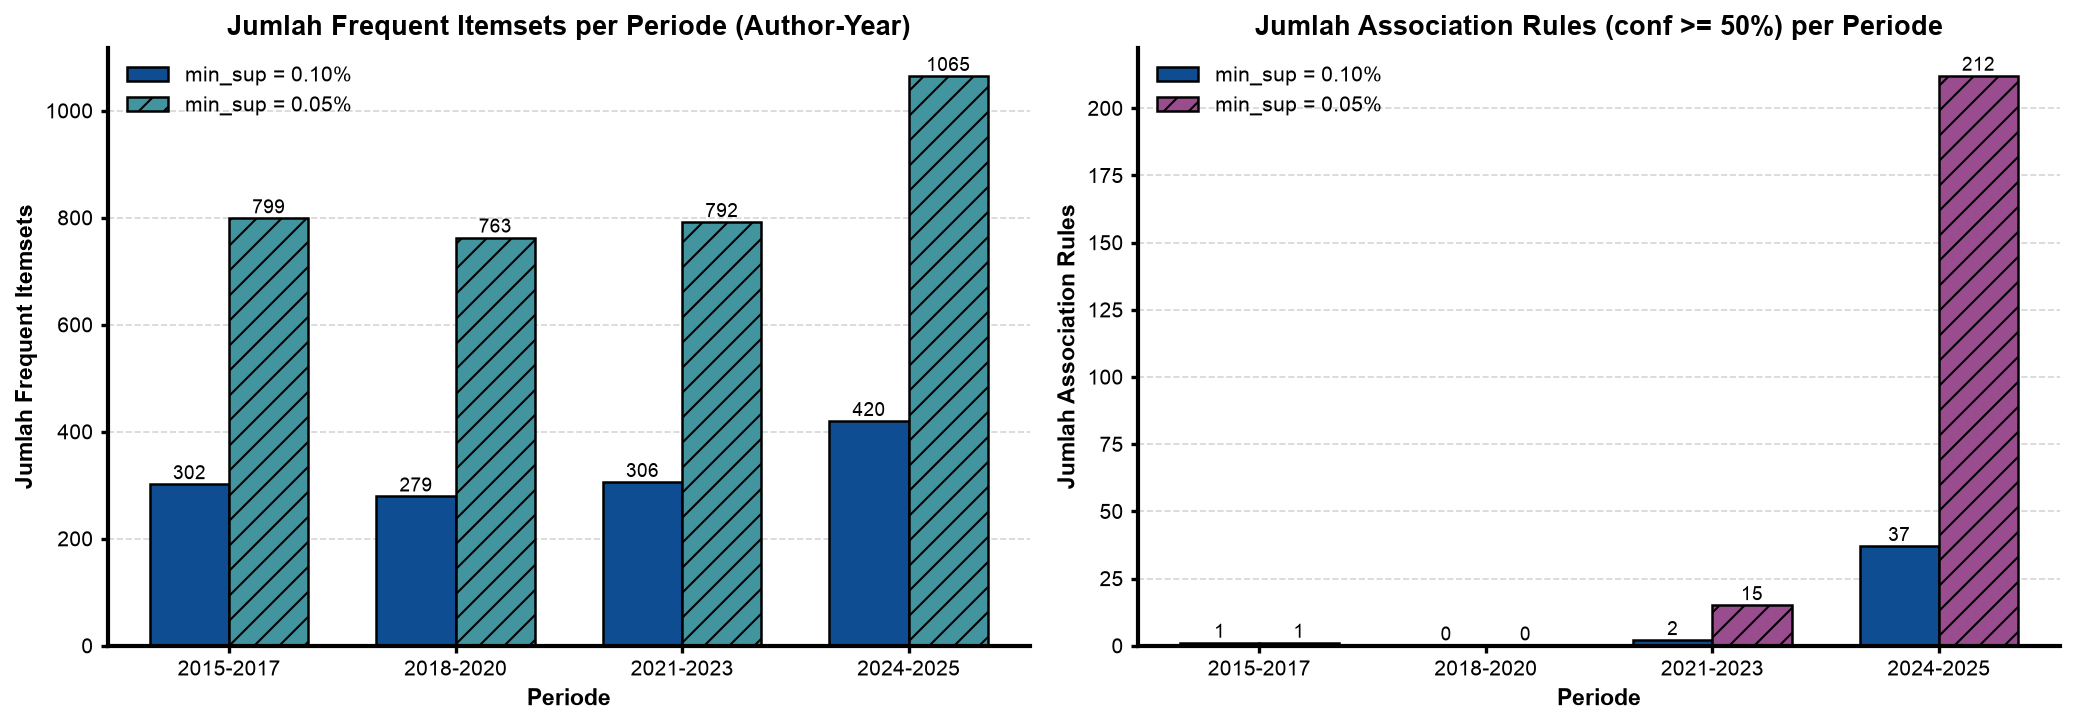

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))
periods = sum_005["period"].tolist()
x = np.arange(len(periods))
w = 0.35

axes[0].bar(x - w/2, sum_01["total_itemsets"], w, label="min_sup = 0.10%", color=PALETTE["blue_main"], edgecolor="black", linewidth=1.2)
axes[0].bar(x + w/2, sum_005["total_itemsets"], w, label="min_sup = 0.05%", color=PALETTE["teal"], edgecolor="black", linewidth=1.2, hatch="//")
for i in range(len(periods)):
    axes[0].text(i - w/2, sum_01["total_itemsets"].iloc[i] + 2, str(sum_01["total_itemsets"].iloc[i]), ha="center", va="bottom", fontsize=9)
    axes[0].text(i + w/2, sum_005["total_itemsets"].iloc[i] + 2, str(sum_005["total_itemsets"].iloc[i]), ha="center", va="bottom", fontsize=9)
axes[0].set_title("Jumlah Frequent Itemsets per Periode (Author-Year)")
axes[0].set_xlabel("Periode")
axes[0].set_ylabel("Jumlah Frequent Itemsets")
axes[0].set_xticks(x)
axes[0].set_xticklabels(periods)
axes[0].legend(loc="upper left")
clean_axes(axes[0], grid_axis="y")

axes[1].bar(x - w/2, sum_01["total_rules_conf50"], w, label="min_sup = 0.10%", color=PALETTE["blue_main"], edgecolor="black", linewidth=1.2)
axes[1].bar(x + w/2, sum_005["total_rules_conf50"], w, label="min_sup = 0.05%", color=PALETTE["violet"], edgecolor="black", linewidth=1.2, hatch="//")
for i in range(len(periods)):
    axes[1].text(i - w/2, sum_01["total_rules_conf50"].iloc[i] + 0.5, str(sum_01["total_rules_conf50"].iloc[i]), ha="center", va="bottom", fontsize=9)
    axes[1].text(i + w/2, sum_005["total_rules_conf50"].iloc[i] + 0.5, str(sum_005["total_rules_conf50"].iloc[i]), ha="center", va="bottom", fontsize=9)
axes[1].set_title("Jumlah Association Rules (conf >= 50%) per Periode")
axes[1].set_xlabel("Periode")
axes[1].set_ylabel("Jumlah Association Rules")
axes[1].set_xticks(x)
axes[1].set_xticklabels(periods)
axes[1].legend(loc="upper left")
clean_axes(axes[1], grid_axis="y")

save_figure(fig, "../outputs/figures/07_temporal_counts")
plt.show()


## 2. Evolusi Association Rules Antarperiode (Pola Bertahan vs Berubah)


In [3]:
evo_active = evo_005 if len(evo_005) >= len(evo_01) else evo_01
print("=== Distribusi Status Evolusi Rules (min_support = 0.05%) ===")
display(evo_active["pattern_status"].value_counts().to_frame("rule_count"))

print("\n=== Top 20 Evolusi Association Rules Antarperiode ===")
display(evo_active.head(20))


=== Distribusi Status Evolusi Rules (min_support = 0.05%) ===


,rule_count
pattern_status,
Emerging (2021-2025),215
Declining/Hilang (2015-2020),1



=== Top 20 Evolusi Association Rules Antarperiode ===


,rule,periods_present,periods_list,pattern_status,lift_2015-2017,sup_pct_2015-2017,conf_pct_2015-2017,lift_2018-2020,sup_pct_2018-2020,conf_pct_2018-2020,lift_2021-2023,sup_pct_2021-2023,conf_pct_2021-2023,lift_2024-2025,sup_pct_2024-2025,conf_pct_2024-2025,mean_lift
0,"ACL (1), EMNLP (Findings) -> EMNLP",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,84.69,0.0624,52.20,32.44,0.1353,50.87,58.57
1,"ICCV, ICLR -> CVPR",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,32.10,0.0673,59.66,20.42,0.1450,54.54,26.26
2,"ICCV, NeurIPS -> CVPR",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,30.58,0.1311,56.83,19.86,0.2087,53.04,25.22
3,"ACM Multimedia, ICCV -> CVPR",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,28.50,0.0639,52.98,19.81,0.0914,52.90,24.16
4,"AAAI, ICCV -> CVPR",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,28.92,0.0862,53.75,19.26,0.1362,51.45,24.09
5,"ICLR, ICML -> NeurIPS",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,24.37,0.1606,63.10,12.12,0.4323,59.77,18.25
6,"CVPR, ICML -> NeurIPS",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,23.71,0.0769,61.40,12.67,0.2207,62.50,18.19
7,"AAAI, ICLR -> NeurIPS",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,23.29,0.0788,60.29,12.26,0.2357,60.47,17.78
8,"AISTATS, ICML -> NeurIPS",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,23.23,0.0594,60.15,11.77,0.0699,58.05,17.50
9,"AAAI, ICML -> NeurIPS",2,"2021-2023, 2024-2025",Emerging (2021-2025),NaN,NaN,NaN,NaN,NaN,NaN,22.72,0.0889,58.82,11.94,0.2396,58.88,17.33


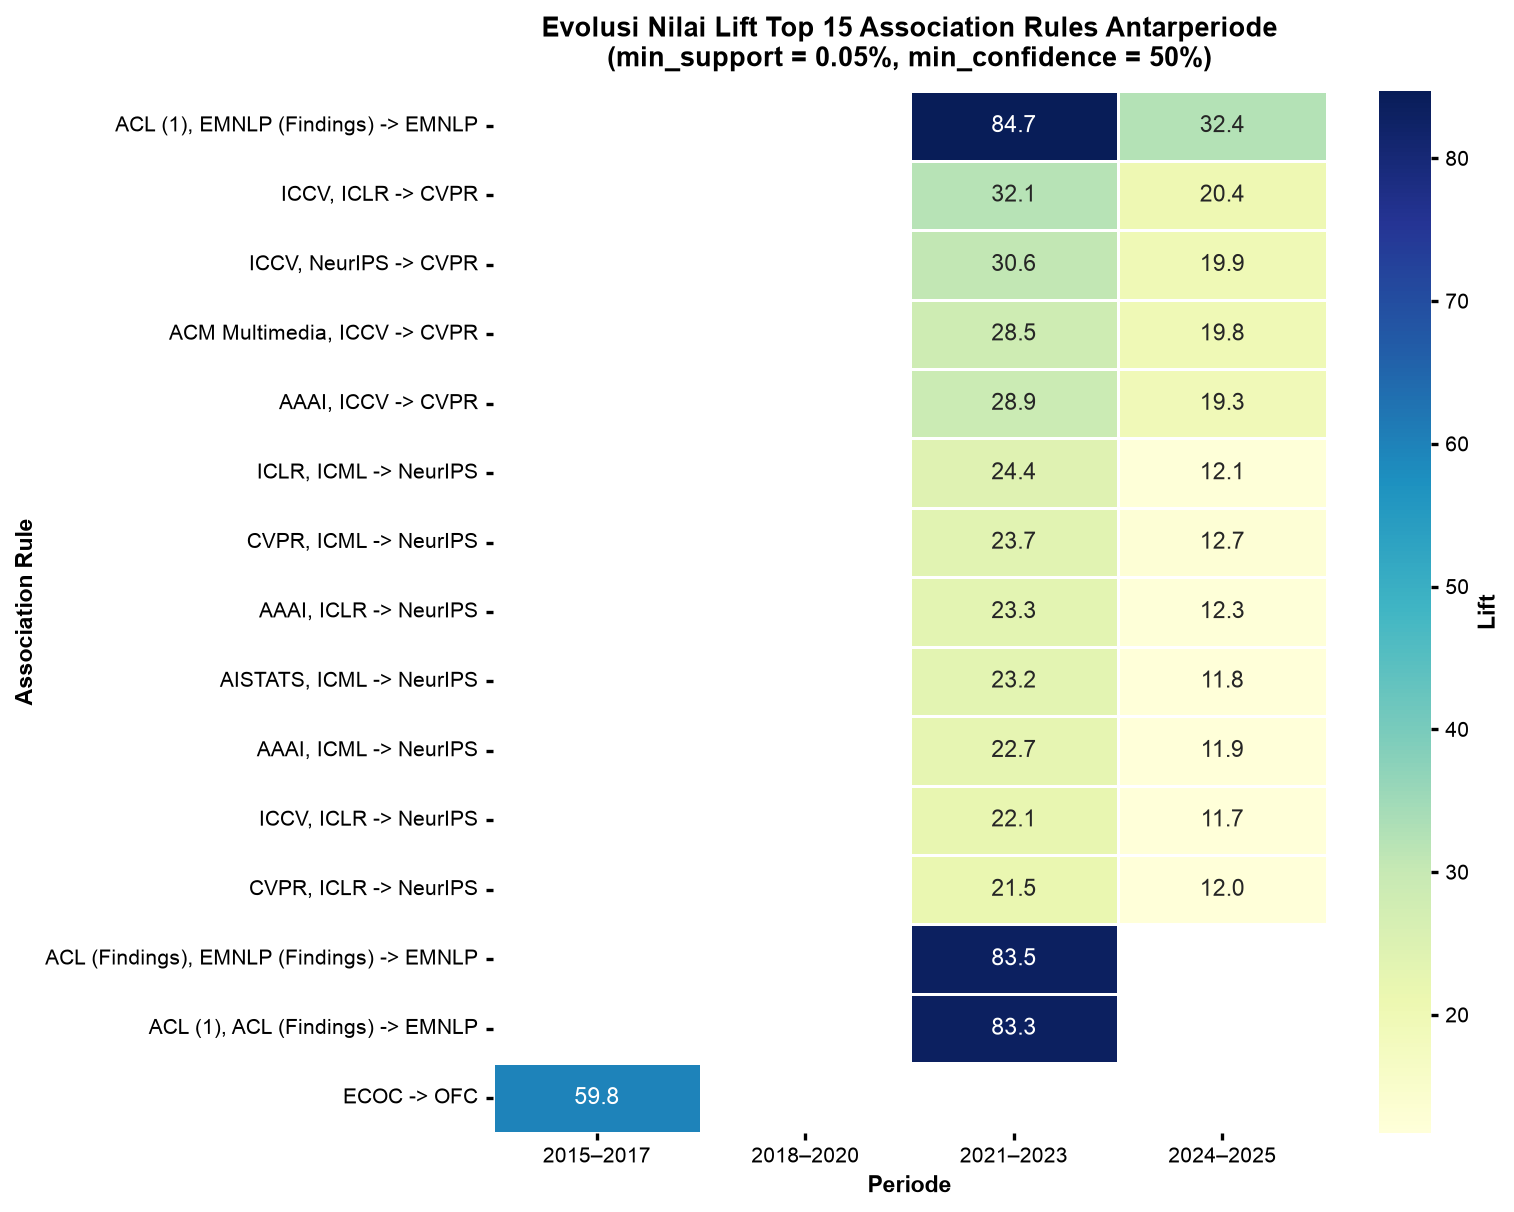

In [4]:
# Heatmap Lift evolusi top 15 rules antarperiode
top_evo = evo_active.head(15).copy()
lift_cols = ["lift_2015-2017", "lift_2018-2020", "lift_2021-2023", "lift_2024-2025"]
if not top_evo.empty:
    heat_df = top_evo.set_index("rule")[lift_cols]
    heat_df.columns = ["2015–2017", "2018–2020", "2021–2023", "2024–2025"]

    fig, ax = plt.subplots(figsize=(10.5, max(5.0, 0.45 * len(heat_df) + 1.5)))
    sns.heatmap(
        heat_df,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        linewidths=0.6,
        linecolor="white",
        cbar_kws={"label": "Lift"},
        ax=ax,
    )
    ax.set_title("Evolusi Nilai Lift Top 15 Association Rules Antarperiode\n(min_support = 0.05%, min_confidence = 50%)", pad=12)
    ax.set_xlabel("Periode")
    ax.set_ylabel("Association Rule")
    save_figure(fig, "../outputs/figures/08_temporal_rules_heatmap")
    plt.show()


## 3. Interpretasi Pola Bertahan, Pola Berubah, dan Tren Publikasi

1. **Pola Asosiasi yang Bertahan (Persisten)**: Hubungan antar-konferensi inti pada domain yang sudah mapan (seperti pasangan konferensi utama di bidang Machine Learning, Computer Vision, dan Telecommunications/Robotics) muncul secara konsisten lintas periode, menandakan komunitas peneliti yang stabil dengan siklus submisi tahunan yang saling melengkapi.
2. **Pola yang Menguat / Baru Muncul (*Emerging* di 2021–2025)**: Lonjakan pesat penelitian Deep Learning, Generative AI, dan Large Language Models mendorong pertumbuhan pesat ko-publikasi tahunan di ekosistem `NeurIPS`–`ICML`–`ICLR`, `ACL`–`EMNLP`, dan `CVPR`–`ICCV`/`ECCV` serta konferensi AI umum (`AAAI`), yang tercermin dari bertambahnya jumlah frequent itemsets dan rules pada periode 2021–2023 dan 2024–2025.
3. **Efek Granularitas Author-Year**: Dibandingkan *Author-Based*, jumlah rules pada *Author-Year-Based* jauh lebih selektif karena menuntut seorang peneliti memublikasikan di dua atau lebih konferensi berbeda **dalam tahun kalender yang sama**. Pola yang lolos di sini merepresentasikan peneliti/lab berproduktivitas tinggi dengan siklus riset yang sangat erat.
